In [1]:
import numpy as np
import pandas as pd

import tubesml as tml
from tubesml.base import BaseTransformer, fit_wrapper, transform_wrapper

import matplotlib.pyplot as plt
%matplotlib inline

/home/lucabasa/Git/kaggle_competitions/nfl_2026/.nfl/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Combine results

In [2]:
df = pd.read_csv("data/combine_results.csv")

df.head()

,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
0,2023,56040,TE,77.875,245,10.000,32.250,79.750,1.60,4.84,38.5,125.0,NaN,NaN,NaN,60,NaN,NaN
1,2023,56010,DB,70.625,191,8.750,29.625,72.250,1.58,4.59,33.5,116.0,NaN,NaN,23.0,60,77.0,74.0
2,2023,56085,TE,79.375,255,10.250,34.000,83.125,1.57,4.55,40.0,128.0,6.87,4.12,23.0,97,65.0,79.0
3,2023,56056,WR,72.250,192,9.625,31.875,76.125,1.51,4.33,NaN,NaN,NaN,NaN,NaN,76,68.0,73.0
4,2023,56118,WR,71.625,191,9.500,31.000,75.000,1.52,4.54,38.5,120.0,6.98,4.15,14.0,65,65.0,64.0


In [4]:
_ = tml.list_missing(df)

Column ten_yd_split: 16.67% missing
Column forty: 16.86% missing
Column vertical: 14.12% missing
Column broad_jump: 17.06% missing
Column three_cone: 64.71% missing
Column short_shuttle: 60.59% missing
Column bench_reps: 62.35% missing
Column ngs_college_production_score: 0.2% missing
Column ngs_final_score: 0.2% missing


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
draft_year,510.0,2024.025490,0.808439,2023.000,2023.0000,2024.000,2025.00000,2025.000
nfl_id,510.0,57331.319608,979.506689,55867.000,56273.5000,57290.000,58302.75000,59278.000
combine_height,510.0,74.579657,2.628102,68.125,72.6250,75.000,76.50000,80.625
combine_weight,510.0,248.380392,53.254702,154.000,198.0000,245.500,304.00000,374.000
hand_size,510.0,9.571814,0.602178,8.000,9.1250,9.500,10.00000,11.625
arm_length,510.0,32.410784,1.419286,28.500,31.3750,32.375,33.50000,36.875
wing_span,510.0,78.465931,3.273243,69.000,76.2500,78.500,80.84375,88.250
ten_yd_split,425.0,1.632000,0.115573,1.460,1.5400,1.590,1.74000,1.960
forty,424.0,4.733514,0.309449,4.280,4.4700,4.620,5.01000,5.480
vertical,438.0,33.810502,4.141179,23.000,31.0000,34.000,37.00000,44.000


In [7]:
df["combine_position"].value_counts()

combine_position
DB    122
OL    121
DL    118
WR    107
TE     42
Name: count, dtype: int64

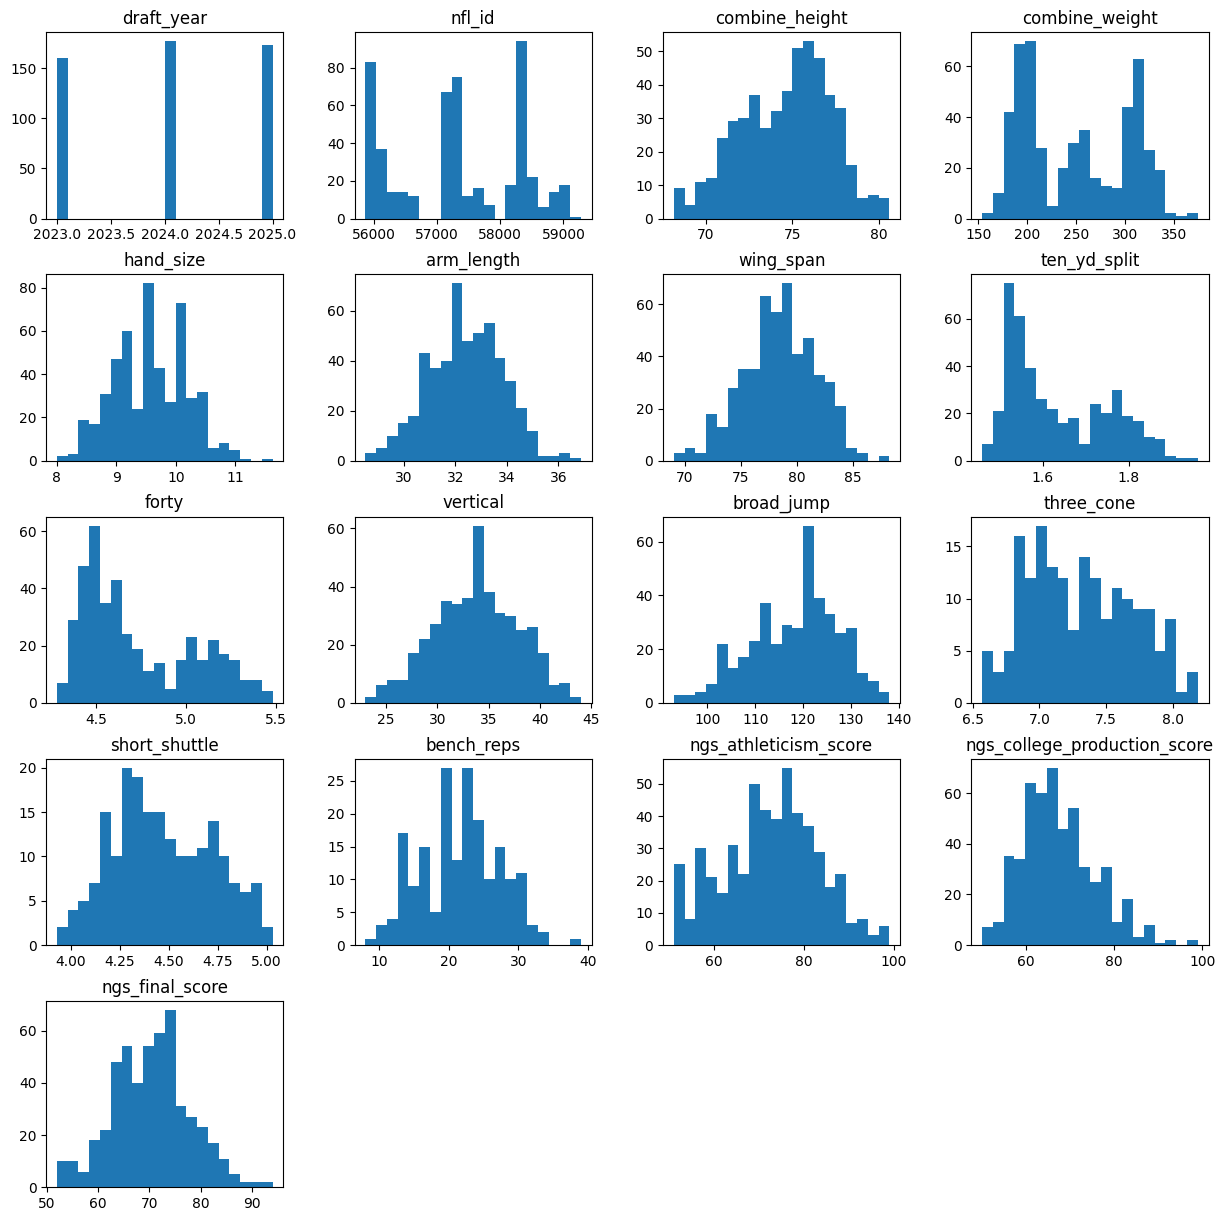

In [12]:
df.hist(bins=20, figsize=(15,15), grid=False)
plt.show()

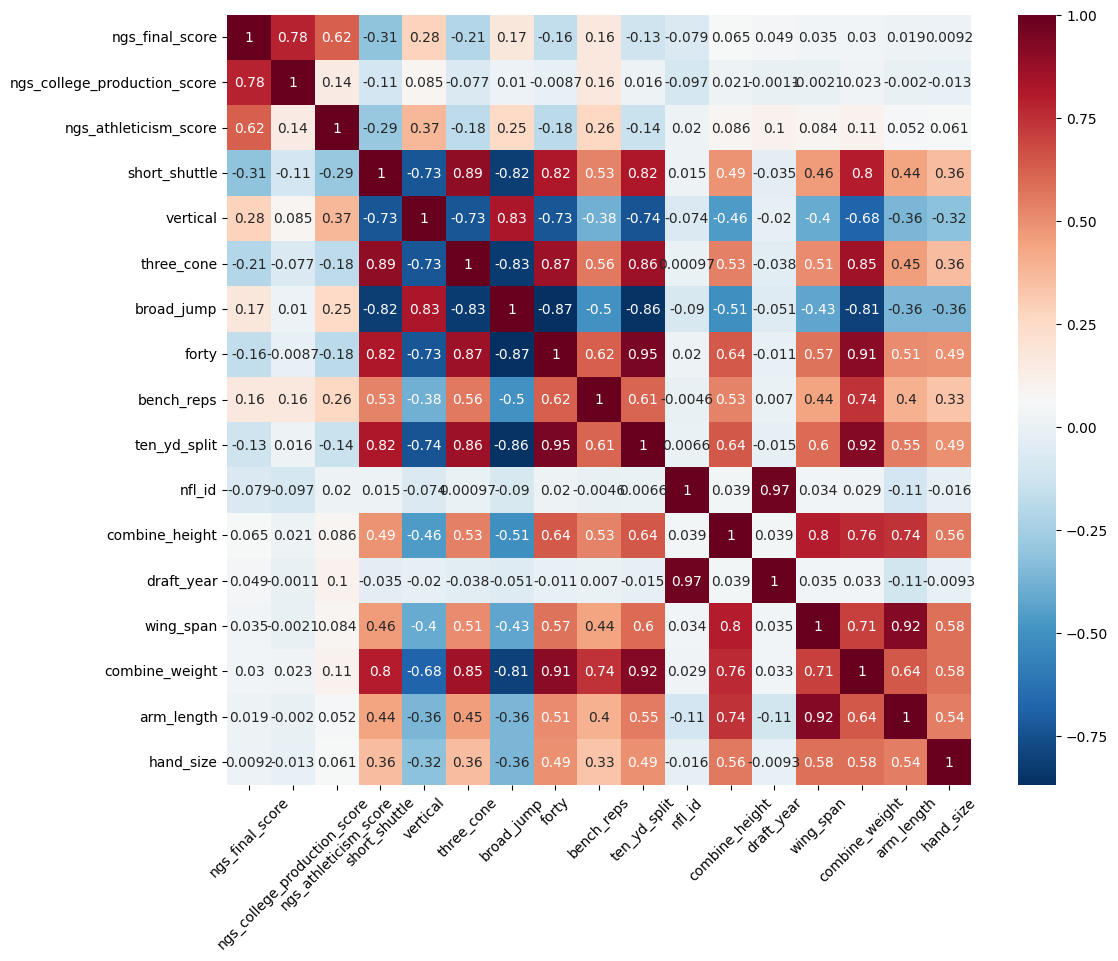

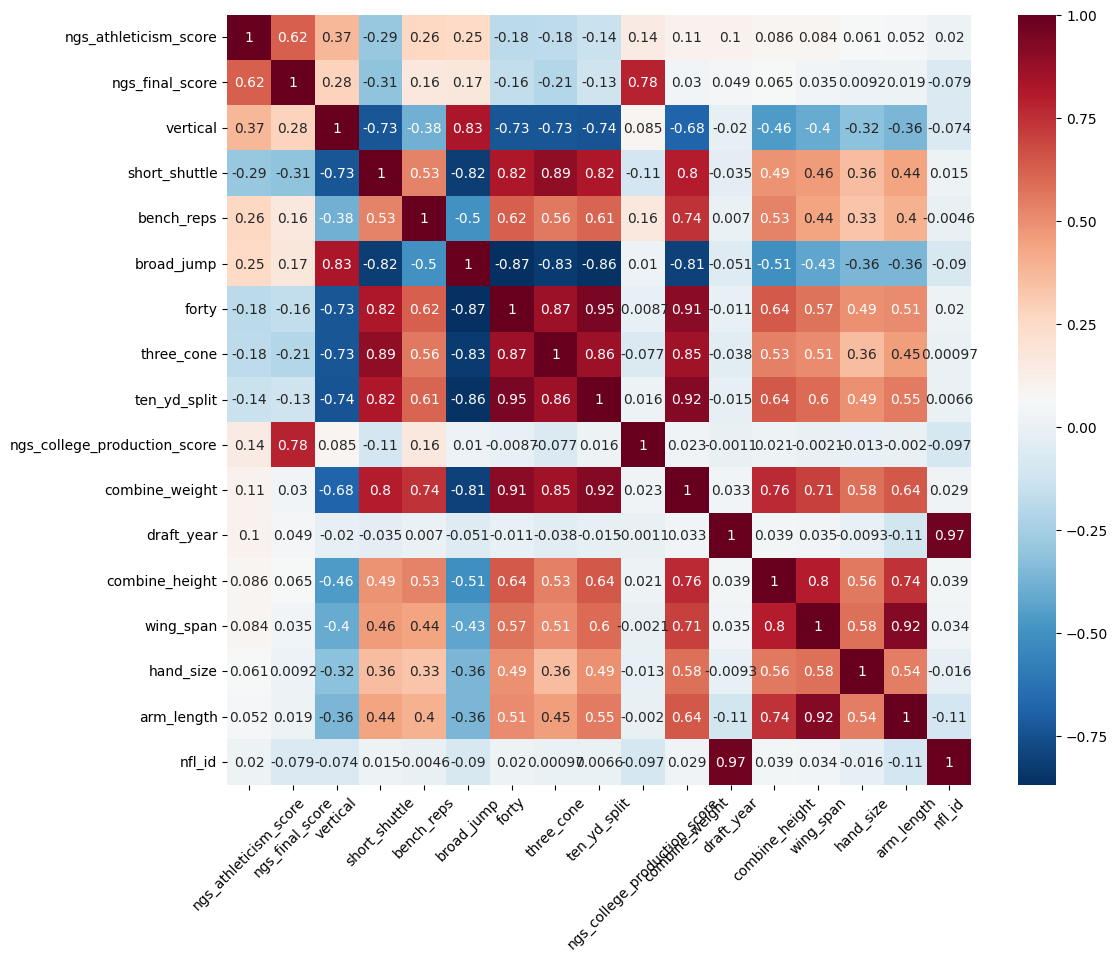

In [14]:
num_cor = tml.plot_correlations(data=df.select_dtypes('number'), target="ngs_final_score", annot=True, limit=20)
num_cor = tml.plot_correlations(data=df.select_dtypes('number'), target="ngs_athleticism_score", annot=True, limit=20)

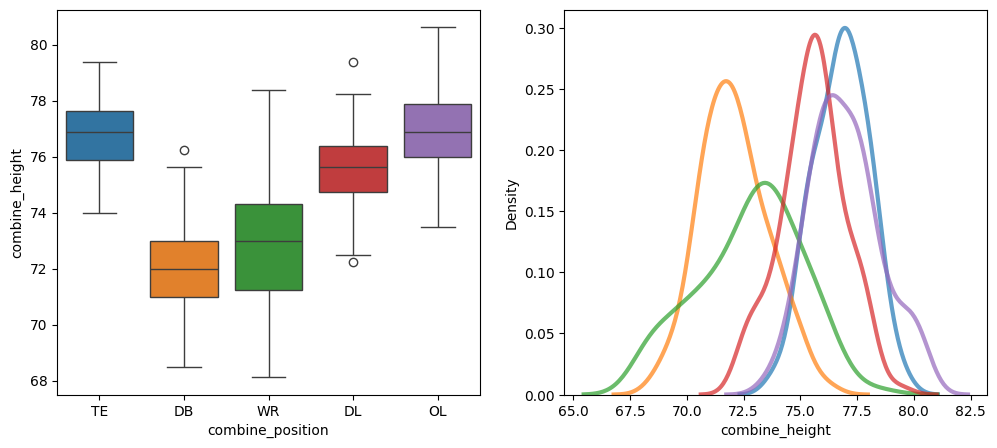

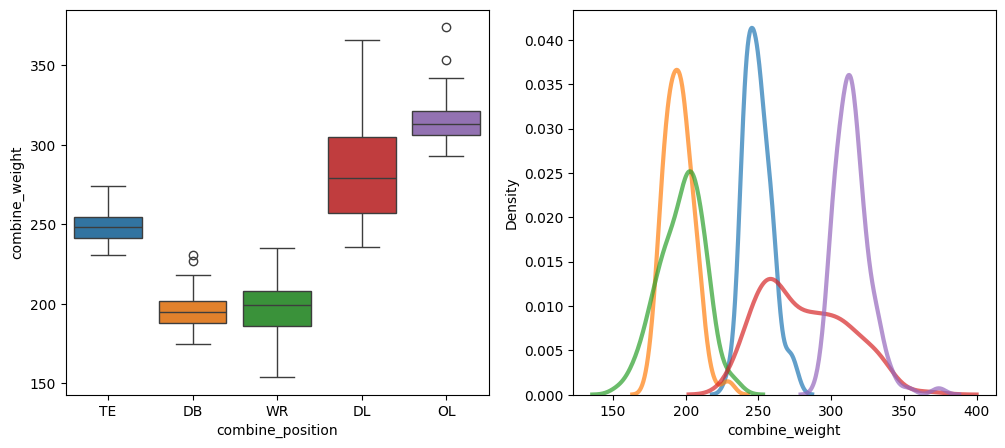

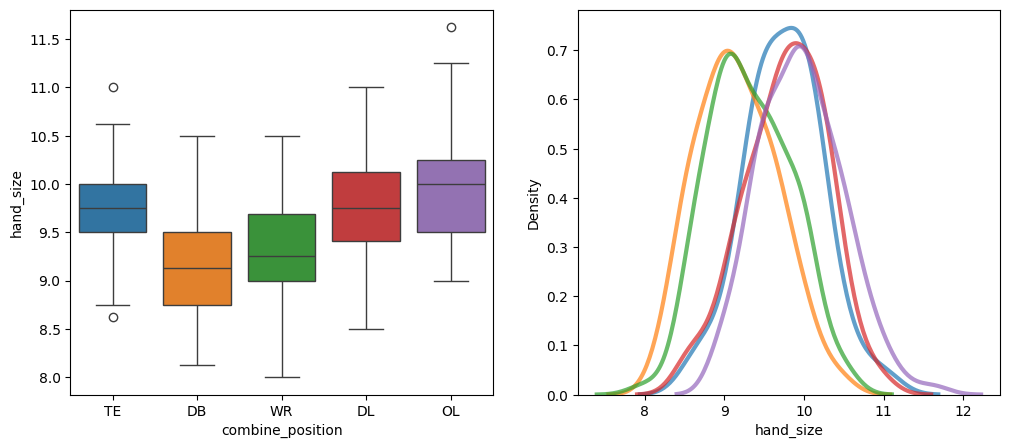

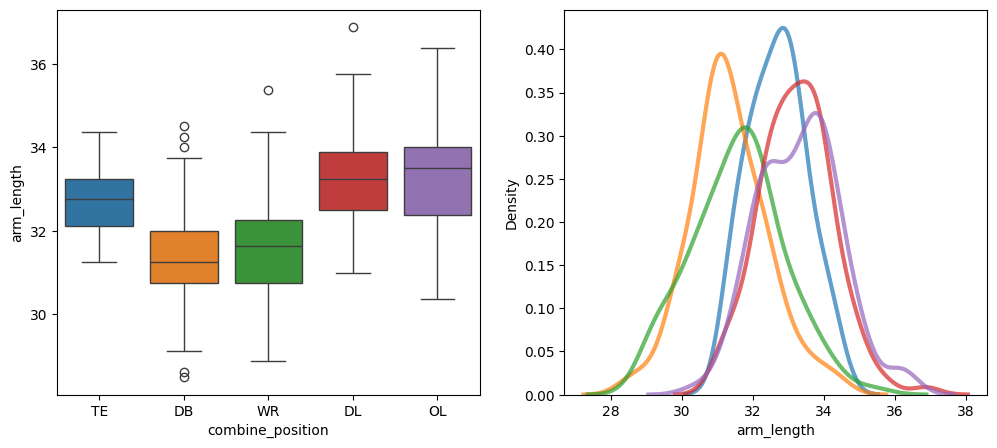

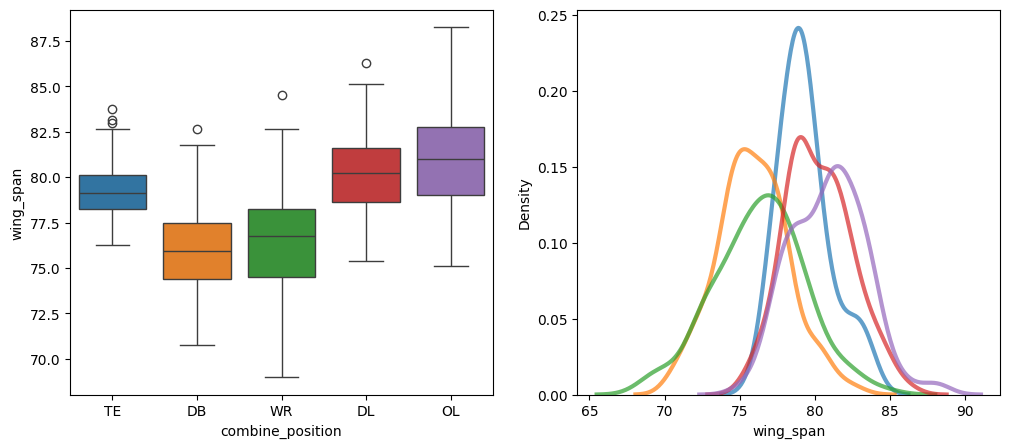

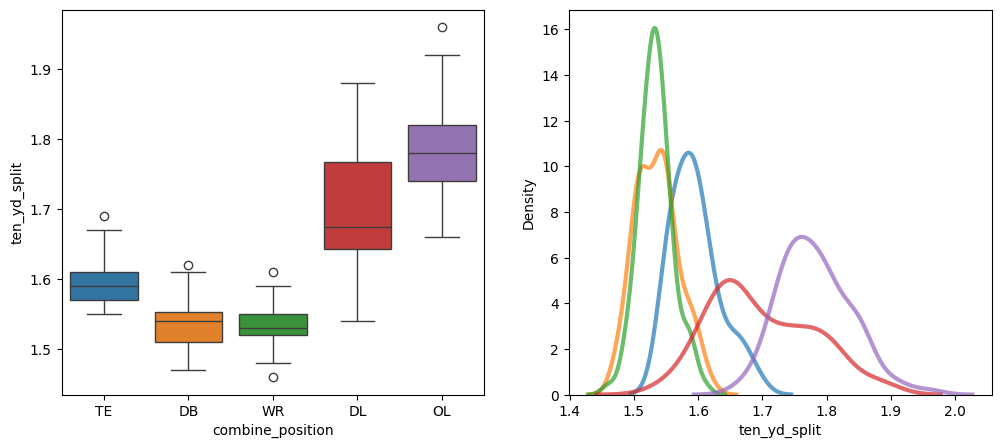

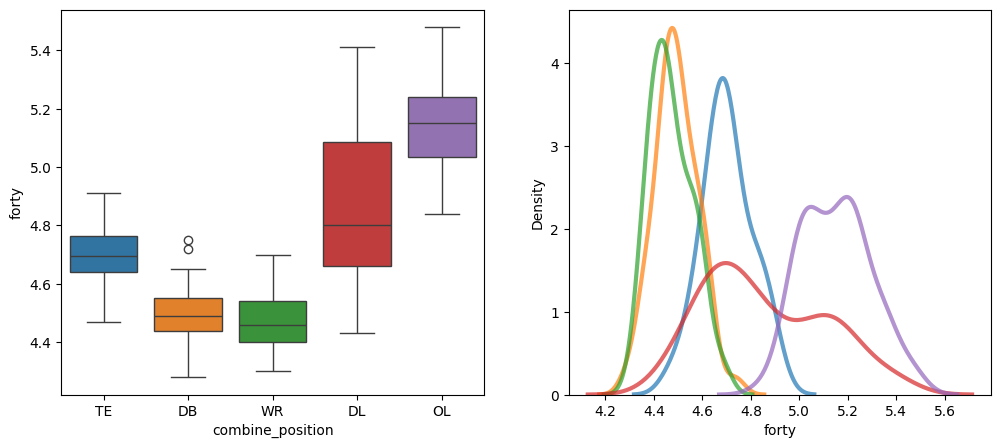

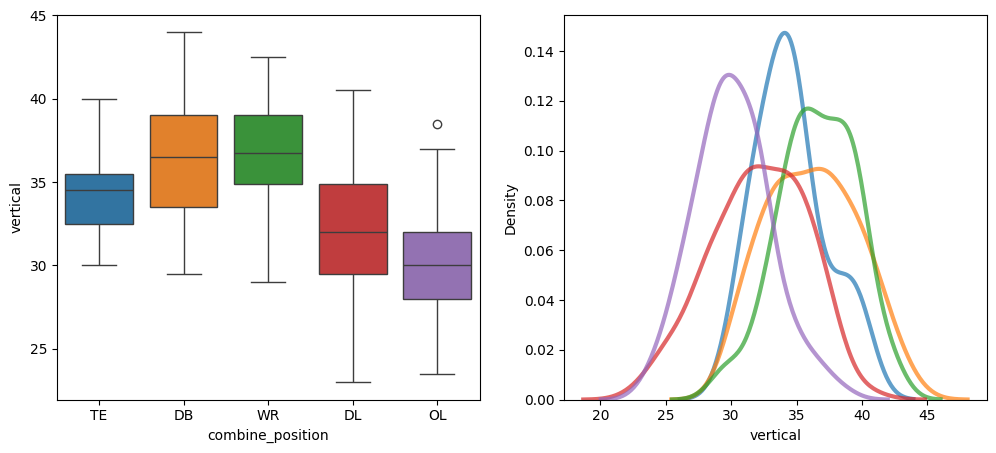

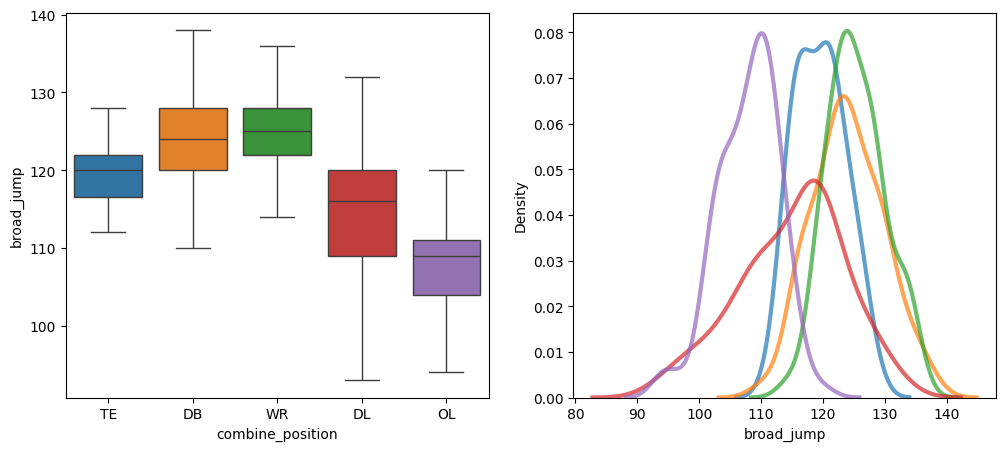

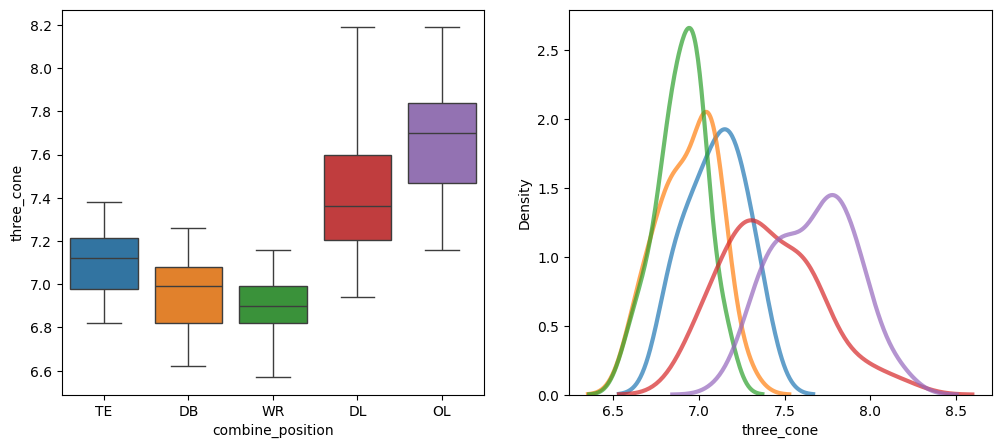

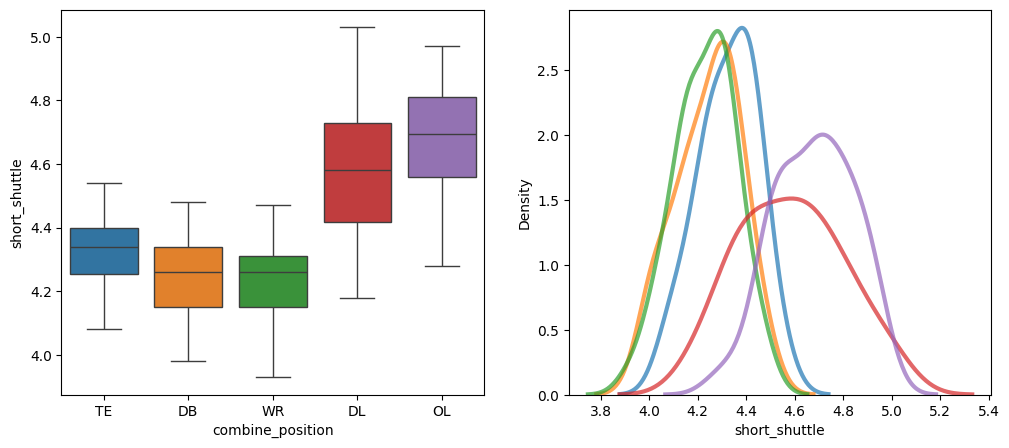

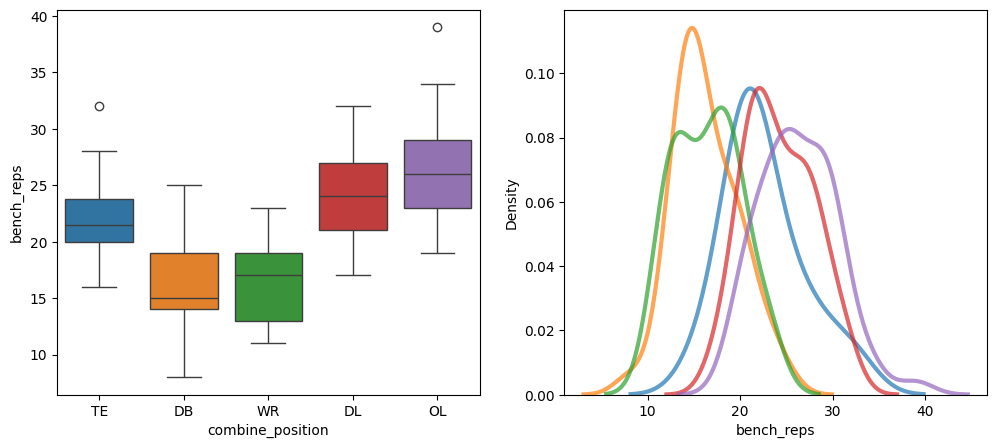

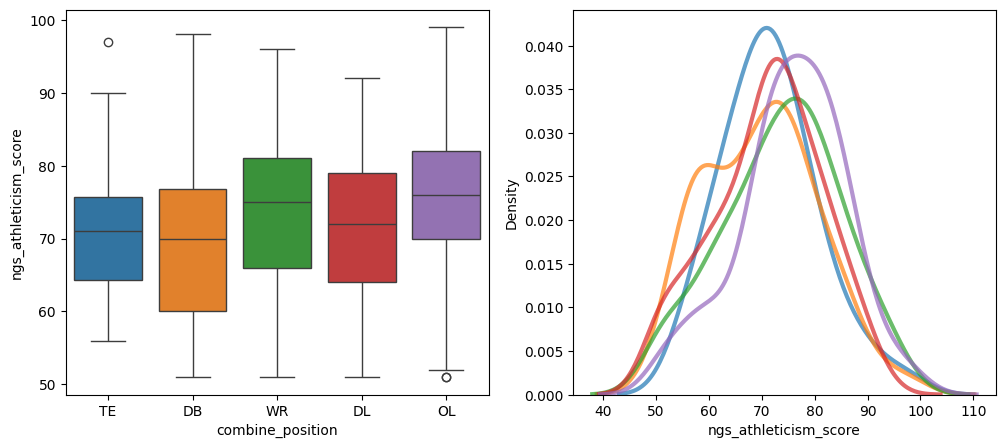

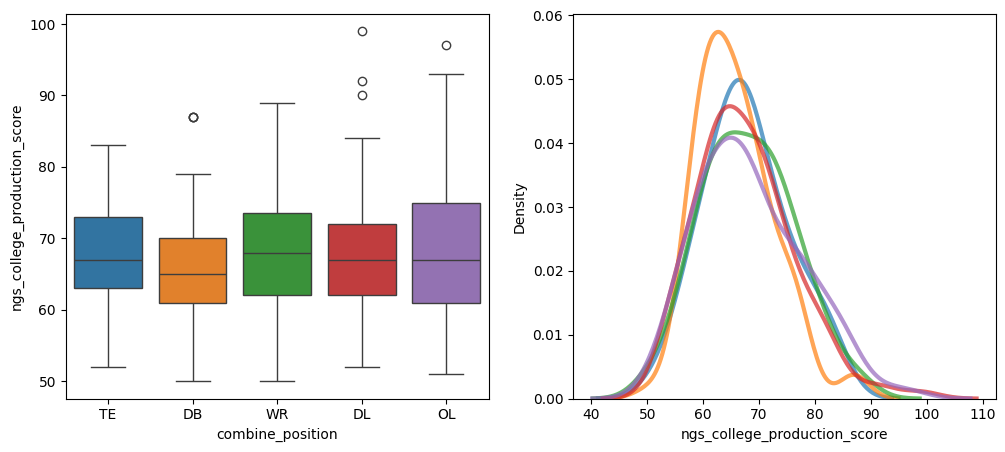

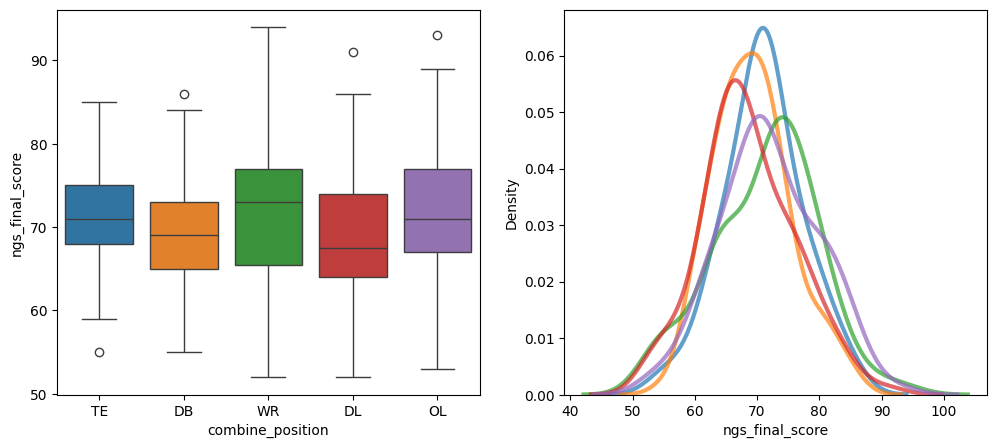

In [17]:
for col in df:
    if col in ['draft_year', 'nfl_id', 'combine_position']:
        continue

    tml.segm_target(data=df, cat="combine_position", target=col)
    

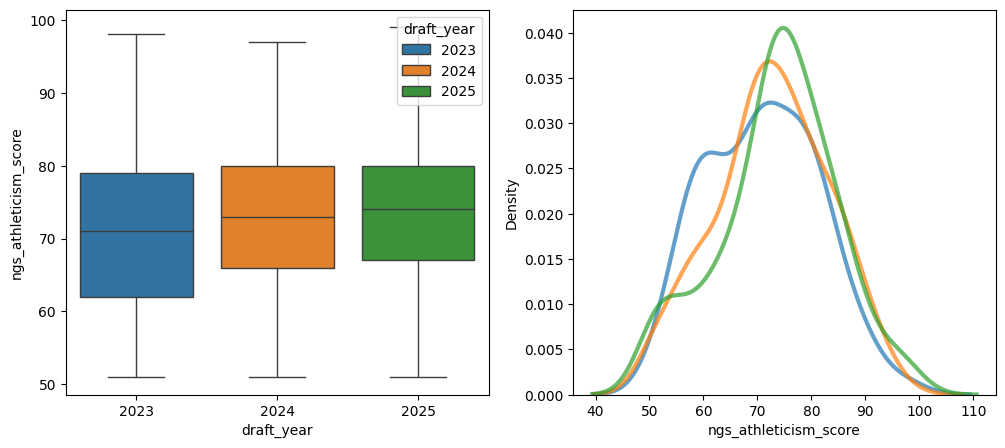

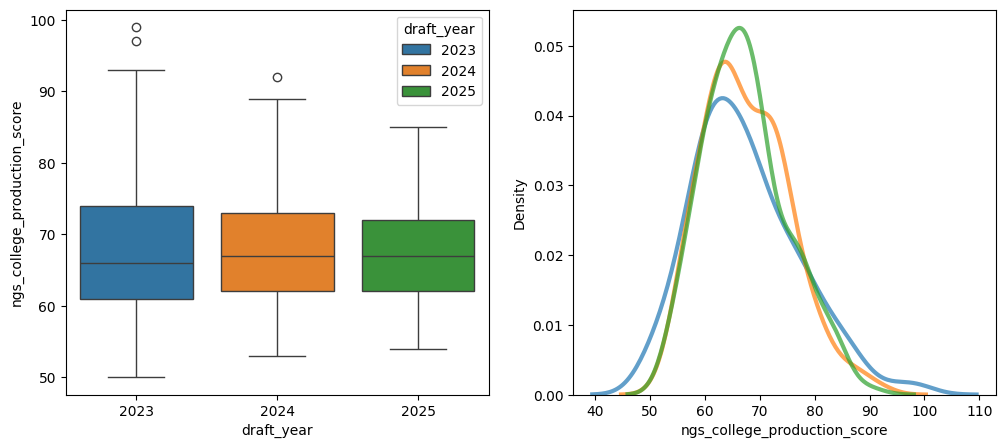

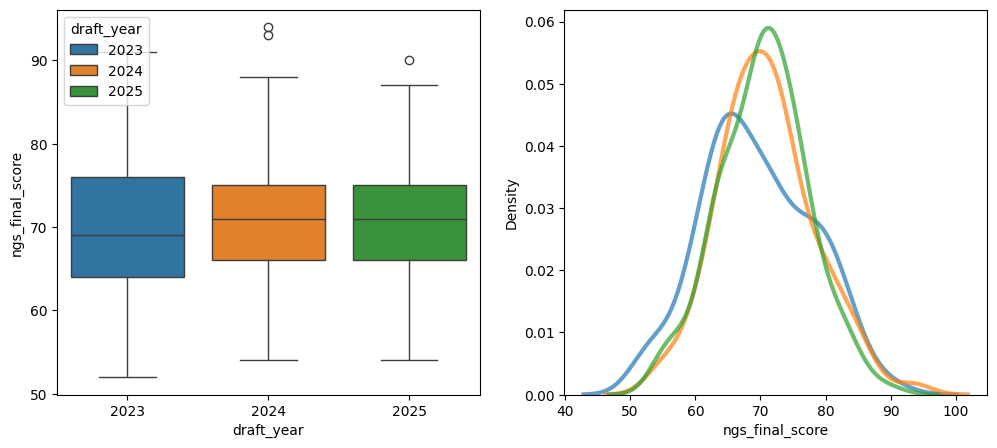

In [18]:
for col in df:
    if "score" in col:
        tml.segm_target(data=df, cat="draft_year", target=col)

# Combine Tracking

In [2]:
df = pd.read_csv("data/combine_tracking.csv")

df["time"] = pd.to_datetime(df["time"])

df.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.200,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.785924,28.285528,0.220828,0.682443,0.011085,250.278576
1,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.300,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.723780,28.297391,0.332931,0.619551,0.003864,257.319206
2,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.400,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.632680,28.279528,0.481838,0.596455,0.008305,253.176813
3,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.500,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.544022,28.243767,0.599350,0.664436,0.007964,247.044153
4,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.600,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.471466,28.210294,0.657540,0.908250,0.005382,240.622668


In [24]:
_ = tml.list_missing(df)

In [25]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
draft_year,463189.0,2024.093223,2023.0,2023.0,2024.0,2025.0,2025.0,0.81987
nfl_id,463189.0,57415.57874,55867.0,56408.0,57331.0,58336.0,59278.0,999.428392
time,463189,2024-04-05 07:13:34.157677056,2023-03-02 20:09:33.900000,2023-03-05 19:03:00.500000,2024-03-02 21:24:27.100000,2025-02-28 23:17:21.400000,2025-03-02 21:22:17.600000,NaN
attempt,463189.0,3.049224,1.0,1.0,1.0,4.0,17.0,3.325315
x,463189.0,44.262522,1.3,34.766667,44.5,48.221888,103.9,17.337613
y,463189.0,24.039636,-11.459799,14.9,26.085594,30.4,66.282837,14.25309
s,463189.0,5.130768,0.0,2.412828,4.92,7.343333,25.794156,3.480071
a,463189.0,2.813108,0.0,1.2468,2.498853,4.089669,44.607283,1.940565
dis,463189.0,0.352934,0.0,0.054444,0.217781,0.49002,45.285317,0.587834
dir,463189.0,149.667876,0.0,88.076853,112.121869,234.173429,359.999689,96.420756


In [3]:
df["drill_name"].unique().tolist()

['OL_PULL_DRILL_FOLD_BLOCK_RIGHT',
 'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT',
 'OL_PULL_DRILL_LONG_PULL_RIGHT',
 'PASS_RUSH_DROP',
 'SCREEN_DRILL',
 'PASS_PRO-MIRROR_DRILL',
 'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE',
 'FORTY_YARD_DASH',
 'THREE_CONE_DRILL',
 'SHORT_SHUTTLE',
 'RUN_THE_HOOP_DRILL',
 'SHORT_ZONE_BREAK_FORWARD',
 'SHORT_ZONE_BREAK_FLAT_WHEEL',
 'SHORT_ZONE_BREAK_INSIDE',
 'PASS_RUSH_DRILL',
 'BODY_CONTROL_DRILL',
 'FOUR_BAG_AGILITY_DRILL',
 'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION',
 'BACK_PEDAL_AND_REACT',
 'RUN_AND_CLUB_DRILL',
 'BOX_DRILL',
 'W_DRILL',
 'LINE_DRILL',
 'TERYL_AUSTIN_DRILL_1',
 'BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION',
 'BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL',
 'TERYL_AUSTIN_DRILL_2',
 'GAUNTLET_DRILL',
 'OVER_SHOULDER_ADJUST',
 'CORNER_ROUTE',
 'FLAT_ROUTE_LEFT',
 'HOOK_ROUTE_RIGHT',
 'BLOCK_EXPLOSION',
 'END_ZONE_FADE_RIGHT',
 'IN_ROUTE_LEFT',
 'WHEEL_ROUTE_LEFT',
 'POST_CORNER_ROUTE_RIGHT',
 'GO_ROUTE_RIGHT',
 'CIRCUS_ROUTE_LEFT',
 'SLANT_ROUTE

In [26]:
for col in ["entity_type", "drill_type", "drill_name"]:
    print(df[col].value_counts())

entity_type
PLAYER    431094
BALL       32095
Name: count, dtype: int64
drill_type
SKILL_DRILLS_WR     120383
SKILL_DRILLS_DB      94623
SKILL_DRILLS_DL      77428
SKILL_DRILLS_OL      61129
FORTY_YARD_DASH      41500
SKILL_DRILLS_TE      37222
THREE_CONE_DRILL     15951
SHORT_SHUTTLE        11690
SKILL_DRILLS_LB       3263
Name: count, dtype: int64
drill_name
FORTY_YARD_DASH                                 41500
GAUNTLET_DRILL                                  38228
BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION    21569
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE          18087
THREE_CONE_DRILL                                15951
FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION     12845
OVER_SHOULDER_ADJUST                            12149
LINE_DRILL                                      11895
FOUR_BAG_AGILITY_DRILL                          11709
SHORT_SHUTTLE                                   11690
PASS_RUSH_DROP                                  10752
POST_CORNER_ROUTE_RIGHT                    

# Game Tracking

In [4]:
df = pd.read_csv("data/game_tracking_2023.csv")

df["time"] = pd.to_datetime(df["time"])

df.head()

,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
0,2024010707,570,56450,2024-01-07 21:46:07.700,42.17,25.29,0.0,0.0,0.0,290.97,213.26,NaN
1,2024010707,570,56450,2024-01-07 21:46:07.800,42.17,25.29,0.0,0.0,0.0,290.97,210.36,NaN
2,2024010707,570,56450,2024-01-07 21:46:07.900,42.18,25.29,0.0,0.0,0.0,290.97,205.45,NaN
3,2024010707,570,56450,2024-01-07 21:46:08.000,42.18,25.29,0.0,0.0,0.0,290.97,200.73,NaN
4,2024010707,570,56450,2024-01-07 21:46:08.100,42.18,25.29,0.0,0.0,0.0,290.97,199.27,NaN


In [5]:
df["event"].unique()

array([nan, 'ball_snap', 'handoff', 'first_contact', 'tackle',
       'man_in_motion', 'run', 'qb_slide', 'qb_sack', 'pass_forward',
       'pass_arrived', 'pass_outcome_caught', 'line_set', 'out_of_bounds',
       'play_action', 'pass_outcome_incomplete',
       'autoevent_passinterrupted', 'touchdown', 'shift',
       'pass_outcome_interception', 'dropped_pass', 'qb_kneel',
       'pass_tipped', 'qb_sneak', 'fumble', 'fumble_defense_recovered',
       'pass_outcome_touchdown', 'play_submit', 'two_point_conversion',
       'qb_strip_sack', 'fumble_offense_recovered',
       'autoevent_playaction', 'lateral', 'penalty_flag', 'qb_spike',
       'penalty_declined', 'touchback', 'huddle_start_offense', 'safety',
       'run_attempt', 'pass_shovel', 'snap_direct',
       'huddle_break_offense', 'penalty_accepted', 'field_goal_attempt'],
      dtype=object)

In [29]:
_ = tml.list_missing(df)

Column event: 93.36% missing


In [31]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
game_id,3665443.0,2023180779.209871,2023080351.0,2023091706.0,2023110501.0,2023121400.0,2024021100.0,253738.207793
play_id,3665443.0,2206.551143,54.0,1151.0,2214.0,3269.0,5196.0,1244.953979
nfl_id,3665443.0,55990.403127,55867.0,55909.0,55939.0,56025.0,56662.0,148.665545
time,3665443,2023-10-30 09:29:41.488235520,2023-08-04 00:12:43.100000,2023-09-17 19:26:35.900000,2023-11-05 18:05:59,2023-12-15 01:19:54.649999872,2024-02-12 03:45:37.200000,NaN
x,3665443.0,60.177652,-5.89,40.98,60.29,79.34,126.73,24.513774
y,3665443.0,26.793436,-7.29,21.04,26.77,32.49,61.24,9.696727
s,3665443.0,2.53081,0.0,0.81,2.08,3.79,12.67,2.127076
a,3665443.0,1.635531,0.0,0.65,1.4,2.35,18.33,1.29381
dis,3665443.0,0.256782,0.0,0.08,0.21,0.38,3.44,0.213518
o,3665443.0,177.683533,0.0,88.21,177.5,268.08,360.0,100.821942


In [32]:
df["event"].value_counts()

event
ball_snap                    50813
pass_forward                 31422
tackle                       29011
first_contact                28345
pass_arrived                 23967
pass_outcome_caught          18845
handoff                      14053
pass_outcome_incomplete      10862
play_action                   8274
out_of_bounds                 6082
autoevent_passinterrupted     4237
run                           2899
qb_sack                       2104
man_in_motion                 1827
line_set                      1610
play_submit                   1264
touchdown                     1174
dropped_pass                   807
pass_outcome_interception      754
pass_outcome_touchdown         646
pass_tipped                    561
fumble                         496
qb_kneel                       493
qb_slide                       419
shift                          397
fumble_offense_recovered       316
fumble_defense_recovered       304
qb_sneak                       293
qb_strip_sack 

# Games

In [33]:
df = pd.read_csv("data/games.csv")

df.head()

,game_id,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
0,2023090700,59173,2023,REG,1,KC,DET
1,2023091000,59174,2023,REG,1,ATL,CAR
2,2023091001,59175,2023,REG,1,BAL,HOU
3,2023091002,59176,2023,REG,1,CLE,CIN
4,2023091003,59177,2023,REG,1,IND,JAX


# Player career successes

In [39]:
df = pd.read_csv("data/player_career_successes.csv")

df["per_starting"] = df["career_games_started"] / df["career_games_active"]
df["total_career_snaps"] = df[[c for c in df if "snaps" in c]].sum(axis=1)
df["offensive_snaps_pg"] = df["career_offensive_snaps"] / df["career_games_active"]
df["defensive_snaps_pg"] = df["career_defensive_snaps"] / df["career_games_active"]
df["special_snaps_pg"] = df["career_special_teams_snaps"] / df["career_games_active"]
df["total_snaps_pg"] = df["total_career_snaps"] / df["career_games_active"]

df["tot_awards"] = df[[c for c in df if "pro_" in c]].sum(axis=1)

df.head()

,nfl_id,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot,per_starting,total_career_snaps,offensive_snaps_pg,defensive_snaps_pg,special_snaps_pg,total_snaps_pg,tot_awards
0,55867,0,1884,92,51,44,1,0,1,0.862745,1976,0.000000,36.941176,1.803922,38.745098,2
1,55870,2802,0,169,47,43,0,0,0,0.914894,2971,59.617021,0.000000,3.595745,63.212766,0
2,55874,3222,0,167,51,49,0,1,0,0.960784,3389,63.176471,0.000000,3.274510,66.450980,1
3,55875,3011,0,170,51,48,0,0,0,0.941176,3181,59.039216,0.000000,3.333333,62.372549,0
4,55877,0,1056,387,51,2,0,0,0,0.039216,1443,0.000000,20.705882,7.588235,28.294118,0


In [40]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
nfl_id,510.0,57331.319608,979.506689,55867.0,56273.500000,57290.000000,58302.750000,59278.000000
career_offensive_snaps,510.0,327.415686,632.400084,0.0,0.000000,0.000000,361.750000,3303.000000
career_defensive_snaps,510.0,234.307843,492.121894,0.0,0.000000,0.000000,220.500000,2666.000000
career_special_teams_snaps,510.0,113.503922,156.194148,0.0,5.000000,53.000000,147.750000,957.000000
career_games_active,510.0,21.721569,16.285063,0.0,6.250000,17.000000,34.000000,51.000000
career_games_started,510.0,7.852941,11.466015,0.0,0.000000,2.000000,12.000000,50.000000
ap_all_pro_1st_team,510.0,0.011765,0.107931,0.0,0.000000,0.000000,0.000000,1.000000
ap_all_pro_2nd_team,510.0,0.003922,0.062561,0.0,0.000000,0.000000,0.000000,1.000000
pro_bowl_original_ballot,510.0,0.027451,0.196310,0.0,0.000000,0.000000,0.000000,2.000000
per_starting,422.0,0.301325,0.323600,0.0,0.000000,0.176471,0.555481,1.000000


# Player play

In [6]:
df = pd.read_csv("data/player_play.csv")

df.head()

,game_id,play_id,team_abbr,nfl_id,lined_up_position,play_description,quarter,down,yards_to_go,possession_team,...,sack,tackle,assist,caused_forced_fumble,recovered_fumble,tackle_for_loss,time_to_pressure,time_to_qb_hurry,coverage_assignment,coverage_assignment_at_snap
0,2025111610,2279,BAL,57183,T,(8:42) (Shotgun) L.Jackson pass incomplete dee...,3,1,10,BAL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026011701,1626,SF,58248,INTERIOR_LINE,(3:48) (Shotgun) K.Walker left end to SEA 28 f...,2,2,7,SEA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025101900,2838,LAR,57140,EDGE,(7:01) C.Van Lanen reported in as eligible. T...,3,2,2,JAX,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO_ASSIGNMENT,NO_ASSIGNMENT
3,2025111300,2628,NYJ,58209,T,(4:05) I.Williams left end to NE 22 for 4 yard...,3,1,10,NYJ,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025121406,2653,NYG,57191,OLB,"(10:08) (No Huddle, Shotgun) M.Mariota scrambl...",3,2,10,WAS,...,0.0,1.0,0.0,0.0,NaN,False,NaN,NaN,HOOK_CURL_LEFT,CURL_FLAT_LEFT


In [7]:
df.columns

Index(['game_id', 'play_id', 'team_abbr', 'nfl_id', 'lined_up_position',
       'play_description', 'quarter', 'down', 'yards_to_go', 'possession_team',
       'yardline_side', 'yardline_number', 'game_clock', 'pre_snap_home_score',
       'pre_snap_visitor_score', 'play_direction',
       'pre_snap_home_team_win_probability',
       'pre_snap_visitor_team_win_probability',
       'home_team_win_probability_added', 'visitor_team_win_probility_added',
       'expected_points_added', 'expected_points', 'offense_formation',
       'receiver_alignment', 'pass_result', 'pass_length',
       'play_nullified_by_penalty', 'penalty_yards',
       'pre_penalty_yards_gained', 'yards_gained', 'team_coverage_man_zone',
       'team_coverage_type', 'in_motion_at_ball_snap', 'target', 'rec_yards',
       'rush_yards', 'yards_after_catch', 'fumble', 'fumble_lost', 'route_ran',
       'separation_at_pass_forward', 'cushion', 'expected_yards_after_catch',
       'dropback_duration', 'extended_sack_allow

In [43]:
_ = tml.list_missing(df)

Column lined_up_position: 0.44% missing
Column yardline_side: 1.31% missing
Column play_direction: 0.02% missing
Column pre_snap_home_team_win_probability: 0.0% missing
Column pre_snap_visitor_team_win_probability: 0.0% missing
Column home_team_win_probability_added: 0.0% missing
Column visitor_team_win_probility_added: 0.0% missing
Column offense_formation: 1.7% missing
Column receiver_alignment: 1.46% missing
Column pass_result: 32.98% missing
Column pass_length: 41.2% missing
Column penalty_yards: 93.4% missing
Column team_coverage_man_zone: 12.39% missing
Column team_coverage_type: 12.39% missing
Column in_motion_at_ball_snap: 50.36% missing
Column rec_yards: 98.01% missing
Column rush_yards: 99.99% missing
Column yards_after_catch: 98.01% missing
Column fumble: 99.98% missing
Column fumble_lost: 99.98% missing
Column route_ran: 83.03% missing
Column separation_at_pass_forward: 85.12% missing
Column cushion: 66.98% missing
Column expected_yards_after_catch: 97.14% missing
Column dr

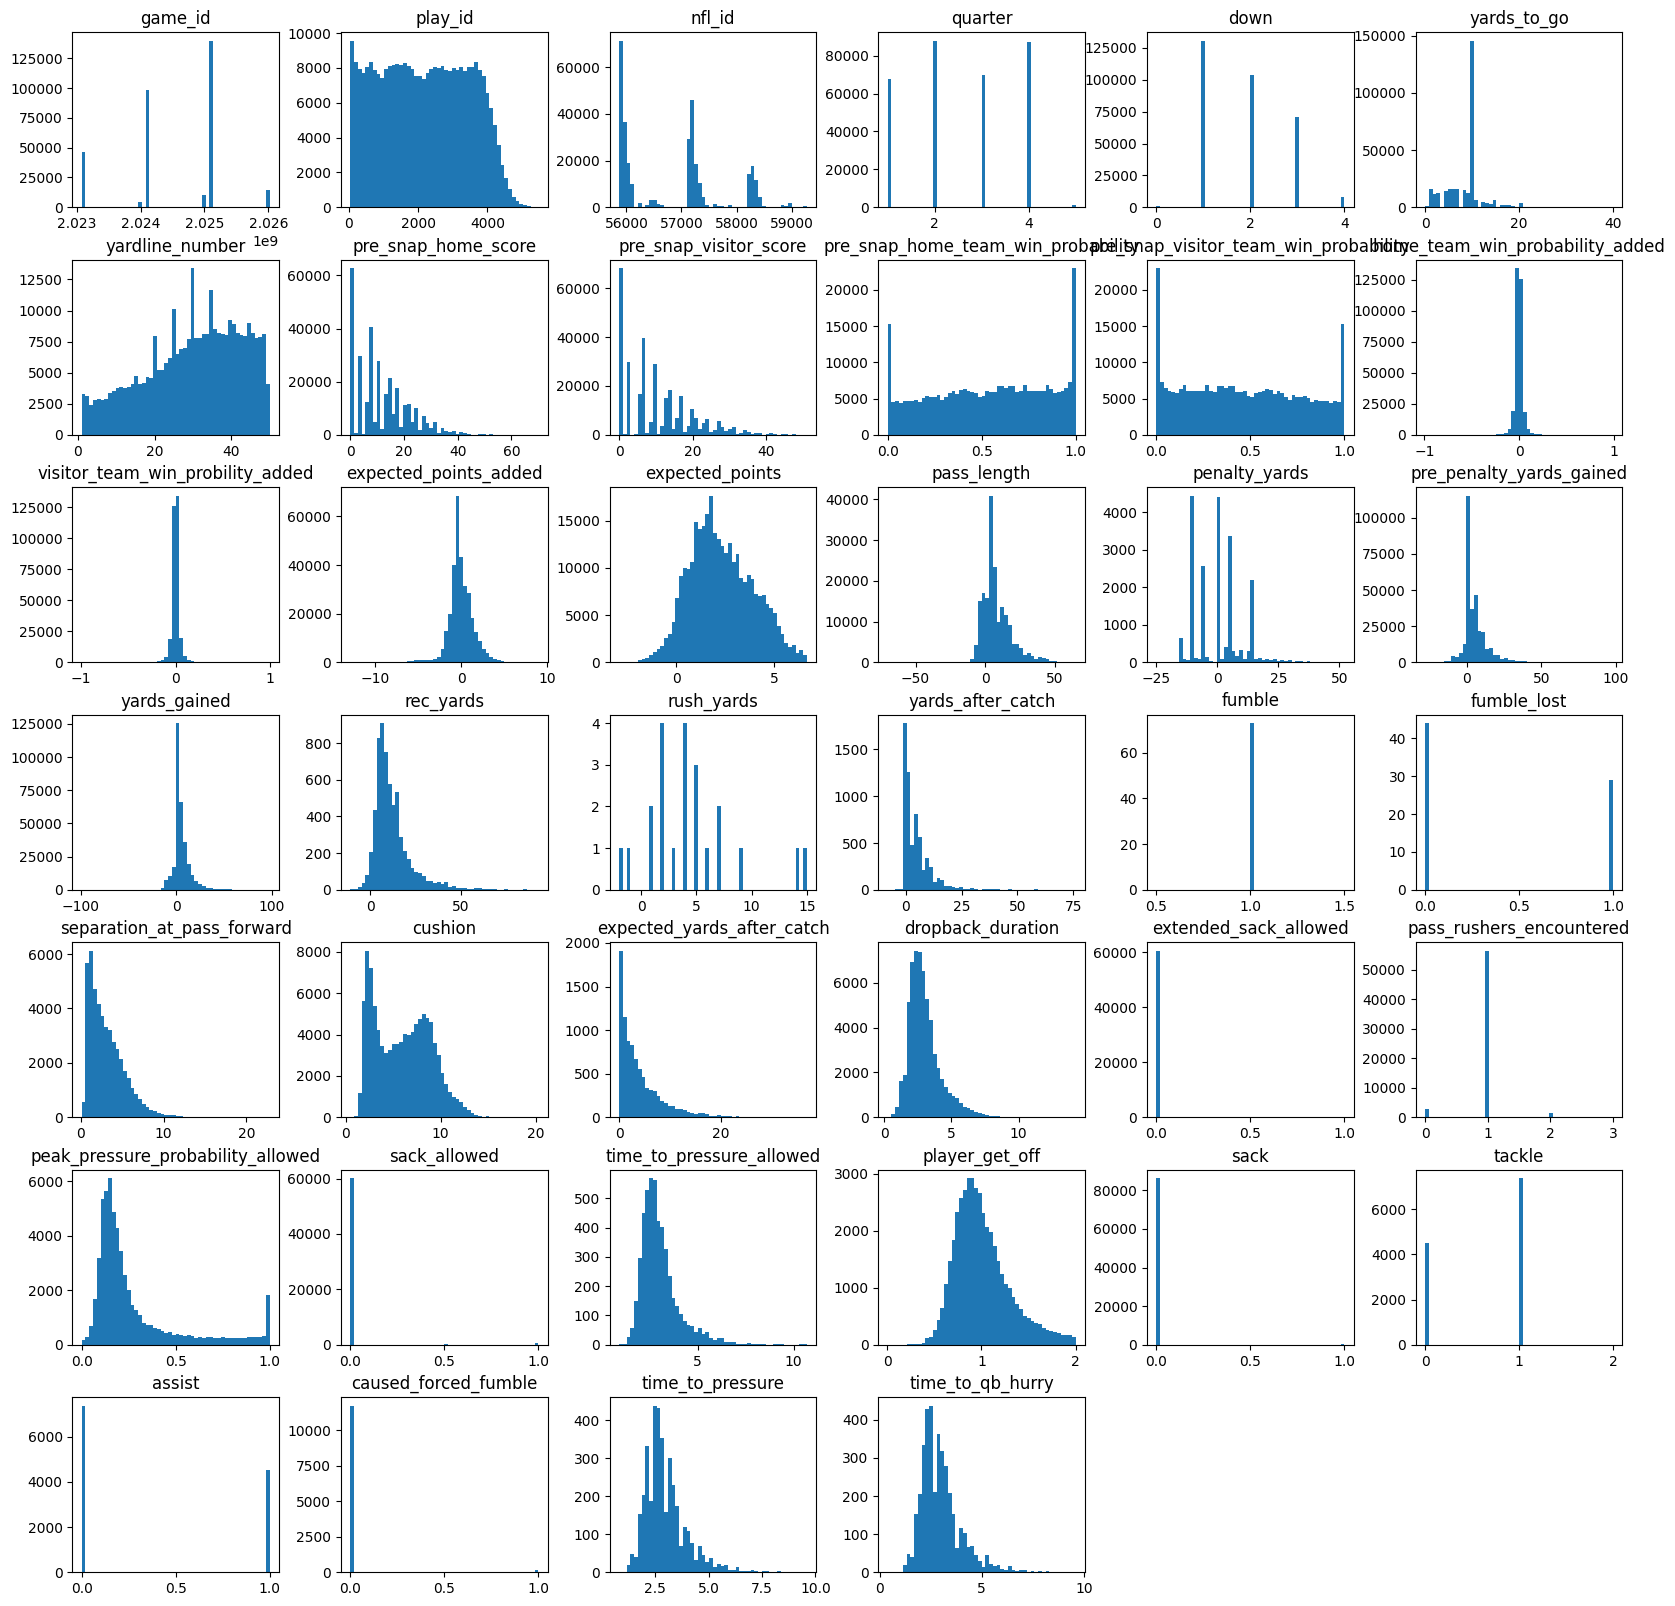

In [45]:
df.hist(bins=50, grid=False, figsize=(20,20))
plt.show()

# Players

In [46]:
df = pd.read_csv("data/players.csv")

df.head()

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.0,3.0,3.0
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.0,6.0,6.0
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1.0,10.0,10.0
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1.0,11.0,11.0
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1.0,13.0,13.0


In [48]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
nfl_id,510.0,57331.319608,979.506689,55867.0,56273.5,57290.0,58302.75,59278.0
draft_year,510.0,2024.025490,0.808439,2023.0,2023.0,2024.0,2025.00,2025.0
draft_round,383.0,4.101828,1.913734,1.0,2.0,4.0,6.00,7.0
draft_pick_within_round,383.0,19.475196,11.184497,1.0,10.0,20.0,28.50,43.0
draft_overall_pick,383.0,126.535248,72.197252,3.0,63.5,122.0,186.00,257.0


In [53]:
df.groupby(["college_conference"])["draft_overall_pick"].agg(["mean", "median"]).sort_values("mean")

,mean,median
college_conference,,
Southland Conference,94.000000,94.0
Missouri Valley Football Conference,98.000000,78.0
Mid-American Conference,100.142857,67.0
Southeastern Conference,114.019048,108.0
Big Twelve Conference,118.274510,104.0
Independent,119.916667,123.0
United Athletic Conference,121.000000,121.0
Pacific Twelve Conference,123.157895,115.5
Big Ten Conference,128.694444,119.0


In [54]:
df.groupby(["college_name"])["draft_overall_pick"].agg(["mean", "median"]).sort_values("mean")

,mean,median
college_name,,
North Dakota State,33.000000,33.0
Toledo,43.500000,43.5
Michigan State,50.000000,50.0
Minnesota,50.666667,48.0
Bowling Green,67.000000,67.0
...,...,...
Jacksonville State,NaN,NaN
Memphis,NaN,NaN
San Jose State,NaN,NaN


In [55]:
df.groupby(["nfl_position"])["draft_overall_pick"].agg(["mean", "median"]).sort_values("mean")

,mean,median
nfl_position,,
T,93.342857,59.0
G,108.641026,91.0
OLB,116.840000,121.0
DE,117.000000,125.0
NT,125.750000,135.5
CB,125.921569,136.0
DT,128.617647,112.0
WR,129.434211,119.0
RB,132.000000,132.0
